Loaded: (15000, 44)

Descriptive statistics:
       Order_Value  Order_Quantity  Package_Weight_KG  Package_Volume_CM3  \
count     15000.00        15000.00           15000.00            15000.00   
mean         82.87            3.29               1.44             2098.26   
std          60.84            1.50               0.85             1656.14   
min           5.46            1.00               0.10              130.00   
25%          42.78            2.00               0.79             1023.75   
50%          66.66            3.00               1.22             1643.00   
75%         104.97            4.00               1.88             2645.25   
max        1172.89           11.00               3.52            19613.00   

       Distance_KM  Warehouse_Processing_Hours  Traffic_Delay_Minutes  \
count     15000.00                    15000.00               15000.00   
mean        194.23                        4.77                  22.12   
std         108.69                        

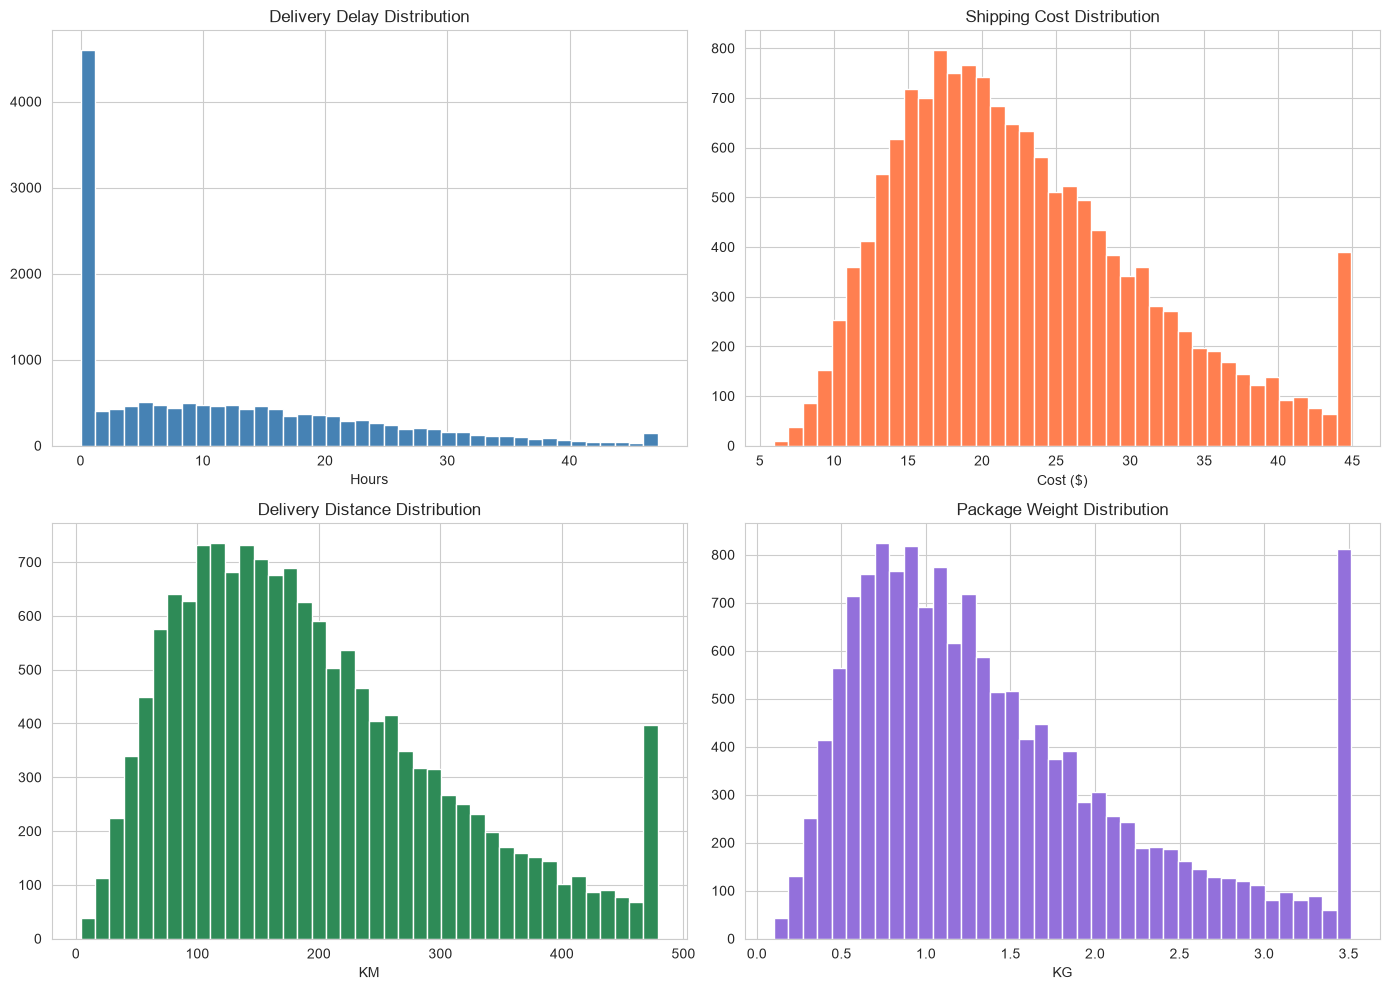

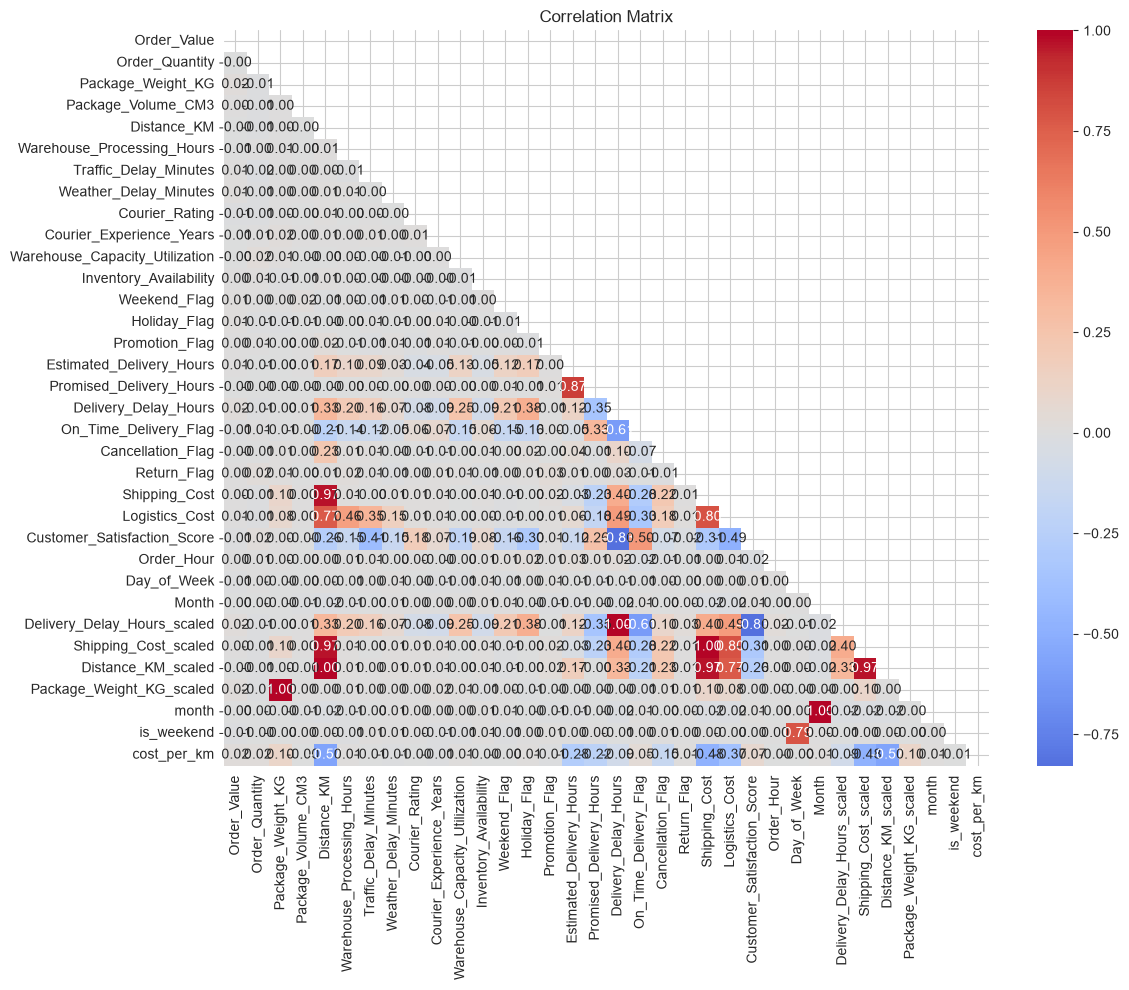

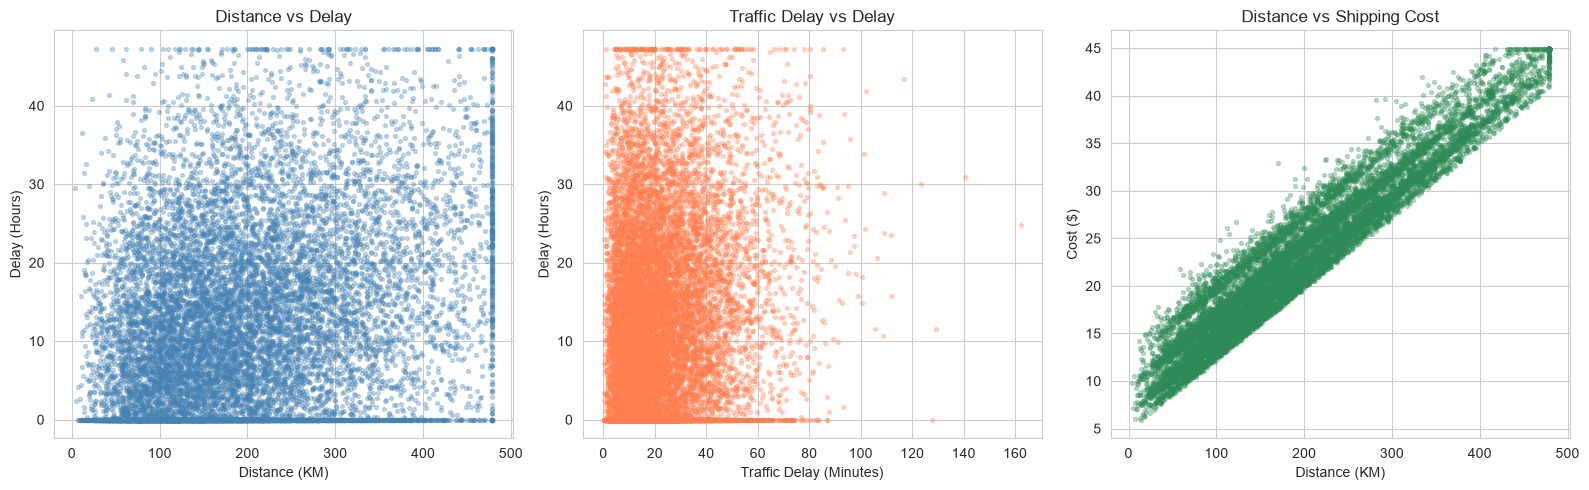

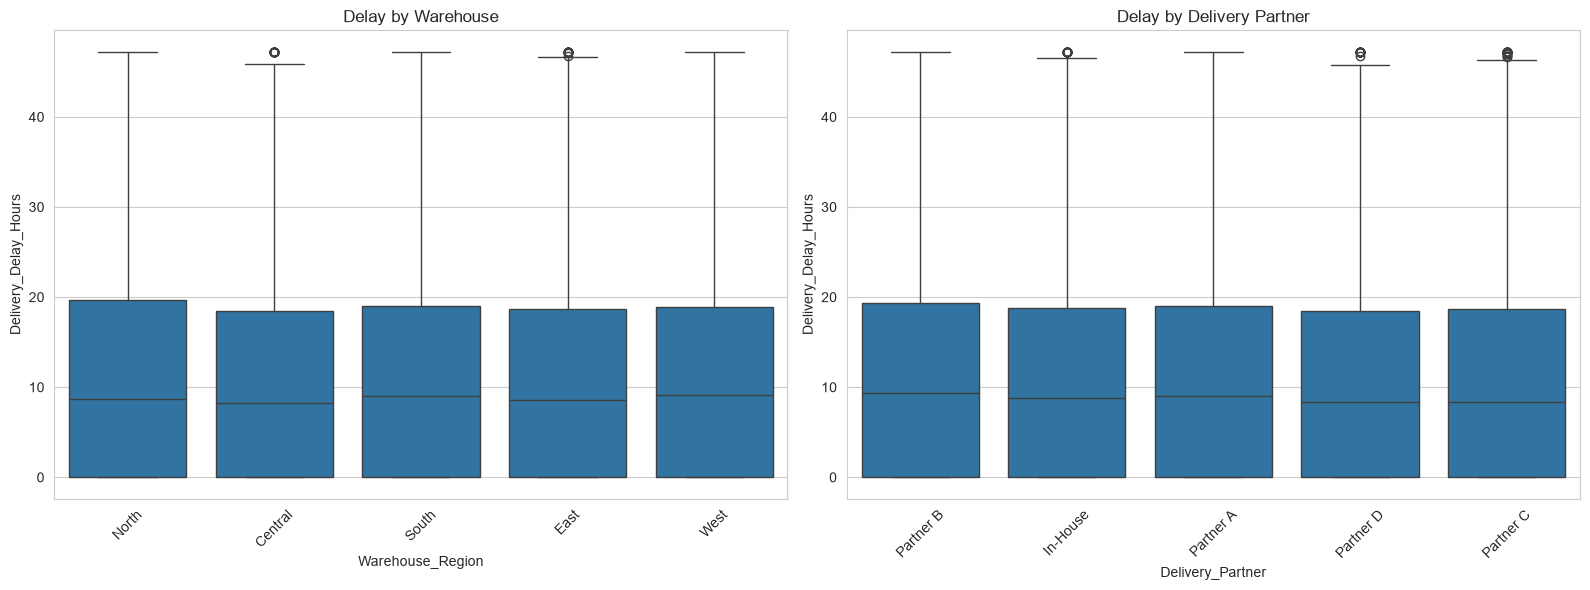

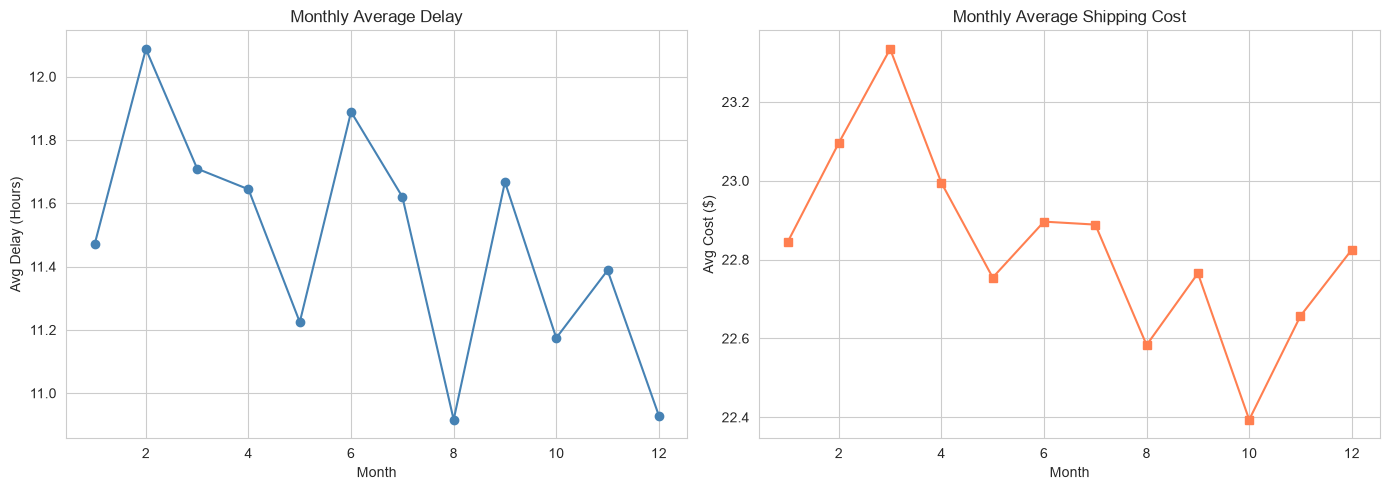


Week 3 done.


In [2]:
"""
Week 3 - Exploratory Data Analysis and Visualization
Logistics Data Analysis Internship
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')


df = pd.read_csv('logistics_data_cleaned.csv')
print("Loaded:", df.shape)


print("\nDescriptive statistics:")
print(df.describe().round(2))


num_cols = df.select_dtypes(include=[np.number]).columns
corr = df[num_cols].corr()

print("\nTop correlations with Delivery_Delay_Hours:")
print(corr['Delivery_Delay_Hours'].sort_values(ascending=False).head(10))



print("\nPerformance by Warehouse Region:")
wh = df.groupby('Warehouse_Region').agg({
    'Delivery_Delay_Hours': 'mean',
    'Shipping_Cost': 'mean',
    'On_Time_Delivery_Flag': 'mean'
}).round(2)
print(wh)




print("\nPerformance by Delivery Partner:")
dp = df.groupby('Delivery_Partner').agg({
    'Delivery_Delay_Hours': 'mean',
    'On_Time_Delivery_Flag': 'mean'
}).round(2).sort_values('Delivery_Delay_Hours')
print(dp)




print("\nBy Shipping Method:")
sm = df.groupby('Shipping_Method').agg({
    'Delivery_Delay_Hours': 'mean',
    'Shipping_Cost': 'mean'
}).round(2)
print(sm)




fig, ax = plt.subplots(2, 2, figsize=(14, 10))

ax[0, 0].hist(df['Delivery_Delay_Hours'], bins=40, color='steelblue')
ax[0, 0].set_title('Delivery Delay Distribution')
ax[0, 0].set_xlabel('Hours')

ax[0, 1].hist(df['Shipping_Cost'], bins=40, color='coral')
ax[0, 1].set_title('Shipping Cost Distribution')
ax[0, 1].set_xlabel('Cost ($)')

ax[1, 0].hist(df['Distance_KM'], bins=40, color='seagreen')
ax[1, 0].set_title('Delivery Distance Distribution')
ax[1, 0].set_xlabel('KM')

ax[1, 1].hist(df['Package_Weight_KG'], bins=40, color='mediumpurple')
ax[1, 1].set_title('Package Weight Distribution')
ax[1, 1].set_xlabel('KG')

plt.tight_layout()
plt.savefig('week3_histograms.png', dpi=150)
plt.show()



plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.savefig('week3_heatmap.png', dpi=150)
plt.show()



fig, ax = plt.subplots(1, 3, figsize=(16, 5))

ax[0].scatter(df['Distance_KM'], df['Delivery_Delay_Hours'],
              alpha=0.3, s=8, color='steelblue')
ax[0].set_xlabel('Distance (KM)')
ax[0].set_ylabel('Delay (Hours)')
ax[0].set_title('Distance vs Delay')

ax[1].scatter(df['Traffic_Delay_Minutes'], df['Delivery_Delay_Hours'],
              alpha=0.3, s=8, color='coral')
ax[1].set_xlabel('Traffic Delay (Minutes)')
ax[1].set_ylabel('Delay (Hours)')
ax[1].set_title('Traffic Delay vs Delay')

ax[2].scatter(df['Distance_KM'], df['Shipping_Cost'],
              alpha=0.3, s=8, color='seagreen')
ax[2].set_xlabel('Distance (KM)')
ax[2].set_ylabel('Cost ($)')
ax[2].set_title('Distance vs Shipping Cost')

plt.tight_layout()
plt.savefig('week3_scatter.png', dpi=150)
plt.show()



fig, ax = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(data=df, x='Warehouse_Region', y='Delivery_Delay_Hours', ax=ax[0])
ax[0].set_title('Delay by Warehouse')
ax[0].tick_params(axis='x', rotation=45)

sns.boxplot(data=df, x='Delivery_Partner', y='Delivery_Delay_Hours', ax=ax[1])
ax[1].set_title('Delay by Delivery Partner')
ax[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('week3_boxplots.png', dpi=150)
plt.show()



df['Order_Date'] = pd.to_datetime(df['Order_Date'], errors='coerce')
df['month_num'] = df['Order_Date'].dt.month

monthly = df.groupby('month_num').agg({
    'Delivery_Delay_Hours': 'mean',
    'Shipping_Cost': 'mean'
})

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(monthly.index, monthly['Delivery_Delay_Hours'], marker='o', color='steelblue')
ax[0].set_xlabel('Month')
ax[0].set_ylabel('Avg Delay (Hours)')
ax[0].set_title('Monthly Average Delay')

ax[1].plot(monthly.index, monthly['Shipping_Cost'], marker='s', color='coral')
ax[1].set_xlabel('Month')
ax[1].set_ylabel('Avg Cost ($)')
ax[1].set_title('Monthly Average Shipping Cost')

plt.tight_layout()
plt.savefig('week3_monthly.png', dpi=150)
plt.show()


